In [93]:
import pandas as pd 

# read the data 
df = pd.read_csv("data/gdsc_expr_postCB.csv")

# visualize the top 5 rows 
df.head(n=5)

# We see that the first column contains the name of the genes and the first row contains names/IDs of the samples 

,Unnamed: 0,906877,906798,906872,906873,906870,906871,906793,906792,906791,...,907317,907318,907319,1299059,684059,684052,684057,687807,684055,1322213
0,ENSG00000000003,2.508729,7.037164,2.577397,7.045888,4.543037,6.801862,5.300144,5.933979,6.911063,...,6.883014,7.880665,7.088381,7.437321,7.009003,6.127656,6.923300,6.758779,7.313623,4.855711
1,ENSG00000000419,8.968814,9.032526,8.567381,8.617857,7.873480,8.888909,8.892322,7.913833,7.615324,...,9.029970,9.084141,8.425315,7.433776,7.935236,8.072725,8.172654,7.131534,8.147621,8.349442
2,ENSG00000000457,4.432231,2.931877,2.560122,2.654424,3.753498,3.204206,3.757574,3.268314,3.680308,...,3.180330,2.901296,2.350121,3.739198,2.957672,3.114235,3.774264,2.935753,3.586686,2.808046
3,ENSG00000000460,3.887446,1.713152,2.167990,2.196951,2.760429,2.628319,2.443053,2.804103,3.997609,...,2.214473,1.844454,1.831997,2.325919,2.352136,2.605327,2.839715,3.004388,2.100455,2.297867
4,ENSG00000000938,2.575608,2.447280,2.777488,2.439445,2.762941,2.919733,2.570636,2.595269,2.643118,...,2.525579,2.739947,2.493749,2.523586,2.359968,2.377841,2.427464,2.811448,2.618779,2.584757


In [13]:
# The libraries we use for dimentionality reduction assume that rows are samples and columns are features which is not the case in transcriptomic data
# so let's transpose the dataframe
df = df.T
df.head(n=5)

,0,1,2,3,4,5,6,7,8,9,...,13931,13932,13933,13934,13935,13936,13937,13938,13939,13940
Unnamed: 0,ENSG00000000003,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,ENSG00000001460,...,ENSG00000261685,ENSG00000261701,ENSG00000261857,ENSG00000263002,ENSG00000263843,ENSG00000264247,ENSG00000264575,ENSG00000265298,ENSG00000265929,ENSG00000266282
906877,2.508729,8.968814,4.432231,3.887446,2.575608,2.586929,5.154627,5.475647,3.21107,2.912748,...,1.4841,1.364339,2.065464,1.887633,2.820525,4.130071,1.433686,7.758634,5.598889,6.081642
906798,7.037164,9.032526,2.931877,1.713152,2.44728,8.277736,6.747967,5.465632,4.995557,2.729889,...,2.399529,0.383567,1.638664,2.924881,1.702484,3.0093,3.261519,5.199038,1.1643,5.581635
906872,2.577397,8.567381,2.560122,2.16799,2.777488,6.430931,6.566853,3.708243,4.132845,1.819089,...,1.96676,0.121532,2.97817,4.424899,1.83243,3.041152,4.051381,6.752677,1.036525,7.312342
906873,7.045888,8.617857,2.654424,2.196951,2.439445,4.854298,7.039492,2.479791,4.044124,1.805946,...,1.496517,0.593483,1.613982,3.335999,2.179198,2.699835,3.245175,6.719169,1.108325,5.444833


In [14]:
# remove the first column and first row
df = df.iloc[1:, 1:]
print("shape of the dataset:", df.shape)

shape of the dataset: (979, 13940)


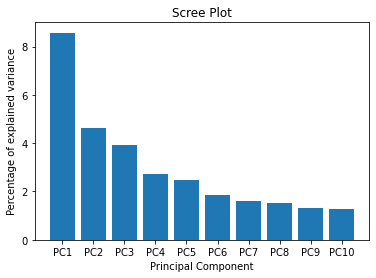

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import numpy as np 
import matplotlib.pyplot as plt


# Standardizing the features
scaled_data = StandardScaler().fit_transform(df)
pca = PCA()
pca_data = pca.fit_transform(scaled_data)

# plot the percentage of variance explained by each of the selected components
per_variation = pca.explained_variance_ratio_ * 100
labels = ["PC" + str(num) for num in range(1, len(per_variation[:10]) + 1)]
plt.bar(x = range(1, len(per_variation[:10]) + 1), 
        height=per_variation[:10], 
        tick_label = labels
)
plt.xlabel("Principal Component")
plt.ylabel("Percentage of explained variance")
plt.title("Scree Plot")
plt.show()

In [6]:
import seaborn as sns
import time

def print_runtime(fn):
    start_time = time.time()
    out = fn()
    print("Took %s seconds" % (time.time() - start_time))
    return out 
    

def visualize2d(xs, ys, dfs, titles, cs):
    f = plt.figure(figsize=(30,10))
    ax1 = f.add_subplot(1, 3, 1)
    ax2 = f.add_subplot(1, 3, 2)
    ax3 = f.add_subplot(1, 3, 3 )
    axs = [ax1, ax2, ax3]
    
    for i, ax in enumerate(axs):
        ax.title.set_text(titles[i])
        ax.scatter(
        x=xs[i], 
        y=ys[i],
        data=dfs[i],
        c=cs[i]
        )

In [7]:
pca = PCA(n_components = 2)
pca_data = print_runtime(lambda: pca.fit_transform(scaled_data))
pca_df = pd.DataFrame(data = pca_data, columns = ["PC1", "PC2"])

Took 0.4814572334289551 seconds


In [8]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2)
tsne_data = print_runtime(lambda: tsne.fit_transform(scaled_data))
tsne_df = pd.DataFrame(data = tsne_data, columns = ["TSNE1", "TSNE2"])

Took 6.124736785888672 seconds


In [9]:
import umap

umap_data = print_runtime(lambda: umap.UMAP().fit_transform(scaled_data))
umap_df = pd.DataFrame(data = umap_data, columns = ["UMAP1", "UMAP2"])

Took 25.561129570007324 seconds


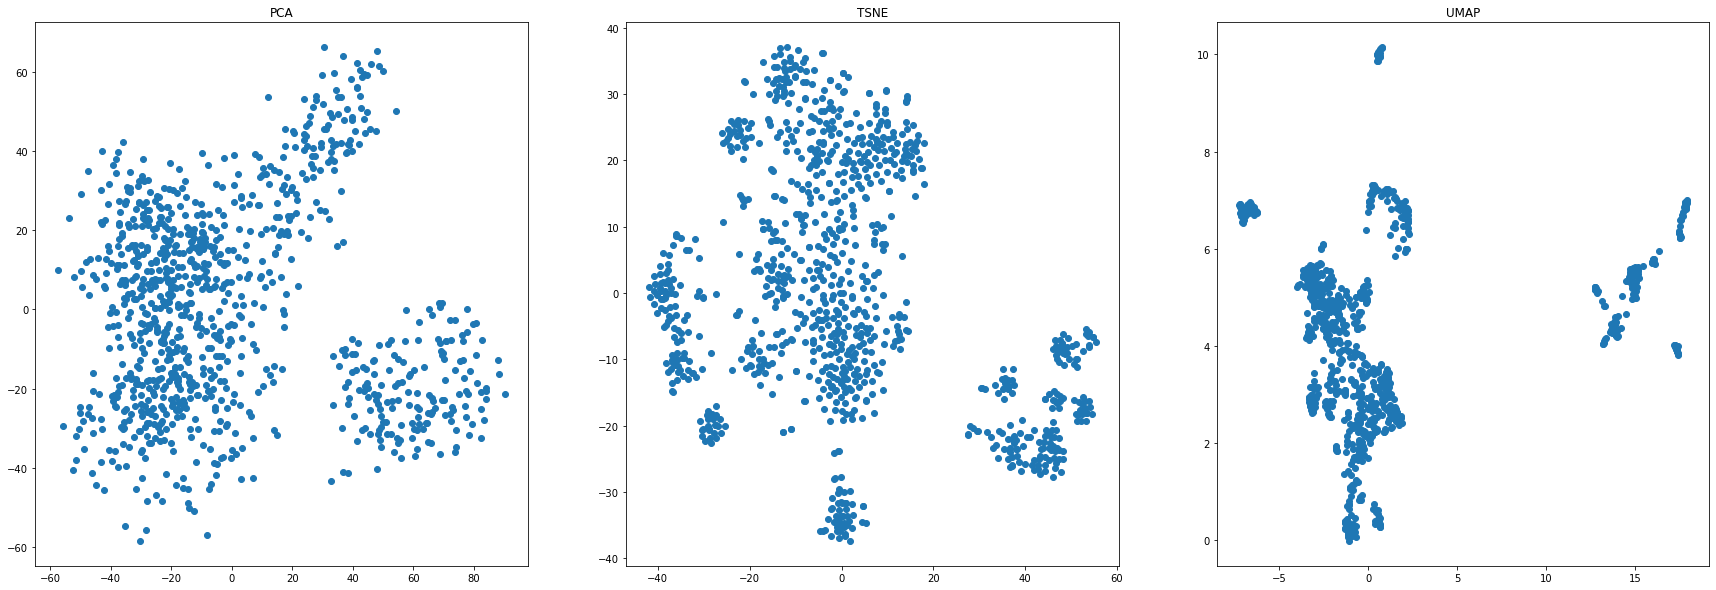

In [10]:
xs, ys = ["PC1", "TSNE1", "UMAP1"], ["PC2", "TSNE2", "UMAP2"] 
dfs = [pca_df, tsne_df, umap_df]
methods = ["PCA", "TSNE", "UMAP"]
visualize2d(xs, ys, dfs, methods, [None, None, None])

In [11]:
from sklearn.cluster import KMeans
import warnings
from sklearn.metrics import silhouette_score

# Ignore windows memory leak warning for kmeans
warnings.filterwarnings('ignore')

k_max = 20
k_range = range(1, k_max)
sse = []
silhouette_coefficients = []
for k in k_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(scaled_data)
    if k != 1:
        silhouette_coefficients.append(silhouette_score(scaled_data, kmeans.labels_))
    sse.append(kmeans.inertia_)

In [12]:
def silhouette_plot(n_clusters, silhouette_coefficients):
    plt.plot(range(2, n_clusters), silhouette_coefficients)
    plt.xticks(range(2, n_clusters))
    plt.xlabel("Number of Clusters")
    plt.ylabel("Silhouette Coefficient")
    plt.title("Silhouette plot")

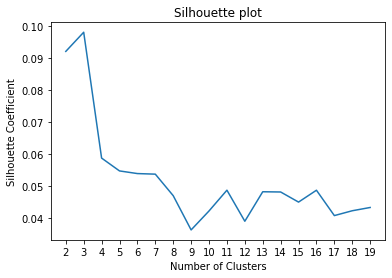

In [13]:
silhouette_plot(20, silhouette_coefficients)

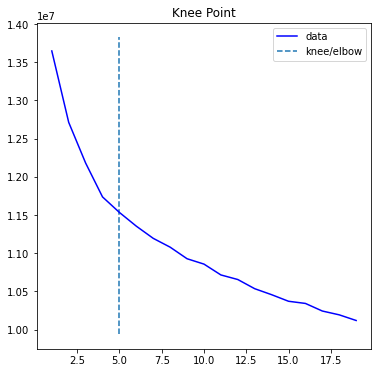

In [14]:
from kneed import KneeLocator

# draw the elbow plot
kl = KneeLocator(range(1, 20), sse, curve="convex", direction="decreasing")
kl.plot_knee()

Took 3.672689437866211 seconds


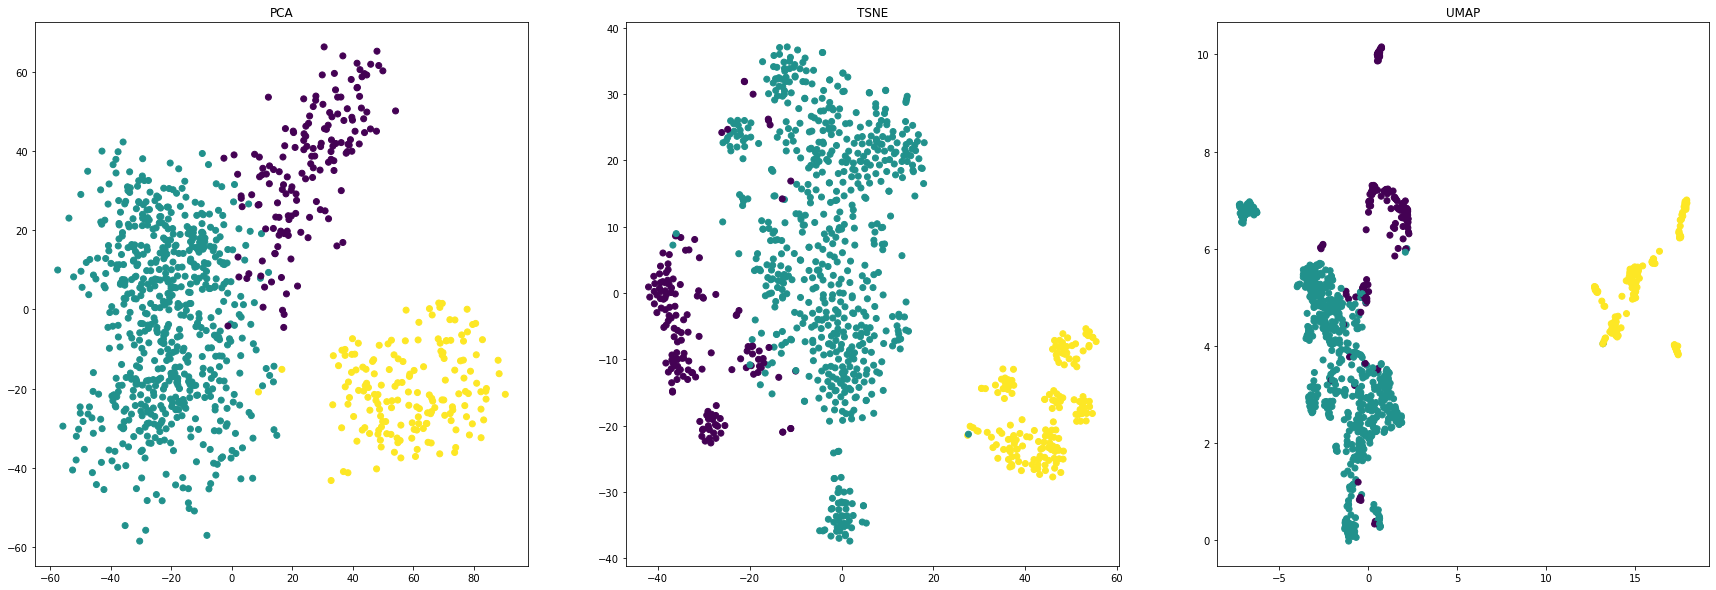

In [18]:
kmeans = KMeans(n_clusters=3, random_state=0)
y_predicted = print_runtime(lambda: kmeans.fit_predict(scaled_data))
for d in dfs:
    d["kmeans"] = y_predicted

visualize2d(xs, ys, dfs, titles=methods, cs=[d["kmeans"] for d in dfs])

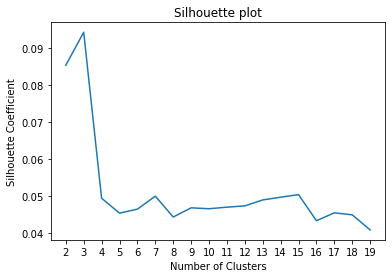

In [17]:
from sklearn.cluster import AgglomerativeClustering

n_clusters = 20
cluster_range = range(2, n_clusters)

silhouette_coefficients = []
for n in cluster_range:
    agglomerative = AgglomerativeClustering(n_clusters=n)
    agglomerative.fit(scaled_data)
    silhouette_coefficients.append(silhouette_score(scaled_data, agglomerative.labels_))

silhouette_plot(20, silhouette_coefficients)

In [45]:
def homogenize_labels(labels):
    """predicted labels are different in agglomerative clustering as k-means
    rearrage the labels (0 to 1 and 1 to 0) for consistency. 
    """
    return np.where((labels==0)|(labels==1), labels^1, labels)

Took 18.285820960998535 seconds


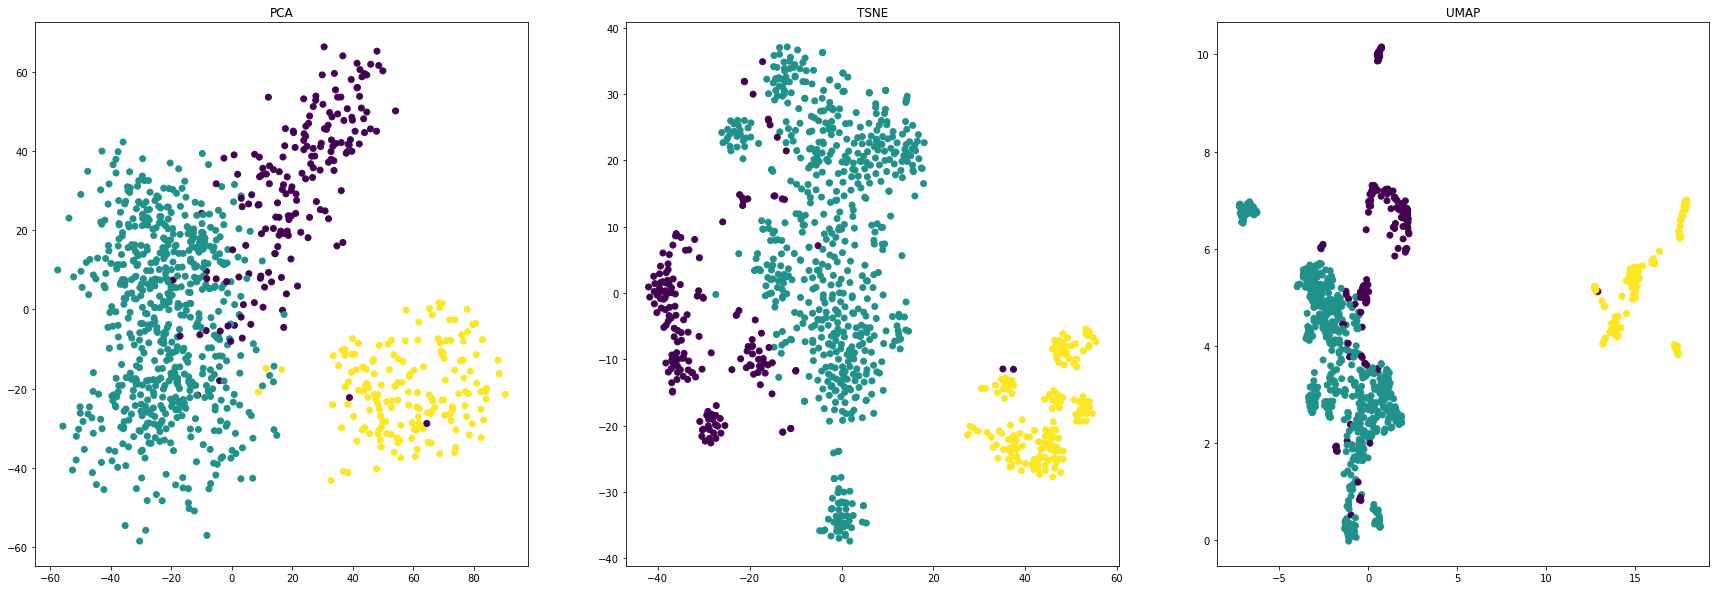

In [46]:
agglomerative = AgglomerativeClustering(n_clusters=3)
y_predicted = print_runtime(lambda: agglomerative.fit_predict(scaled_data))

for d in dfs:
    d["agglomerative"] = homogenize_labels(y_predicted)

visualize2d(xs, ys, dfs, titles=methods, cs=[d["agglomerative"] for d in dfs])    

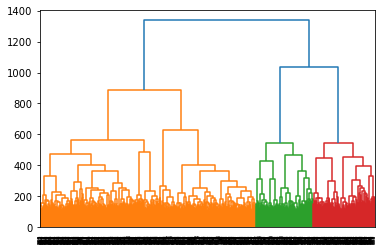

In [20]:
import scipy.cluster.hierarchy as sch
dendrogram = sch.dendrogram(sch.linkage(scaled_data, method="ward", metric="euclidean"))

In [47]:
from sklearn.metrics import jaccard_score

def get_jaccard_table(y1, y2, swap_indexes=False):
    y_pred = []
    y_true = []

    for cluster in range(3):
        # convert multiclass labels to binary before finding binary Jaccard similarity coefficient score
        y_pred.append(np.where(y1 != cluster, 0, 1))
        y_true.append(np.where(y2 != cluster, 0, 1))

    # swap class labels, the same cluster was given different labels by kmeans and agglomerative clustering
    # hacky way of doing it (remove later). Just for the aesthetics of the heatmap. 
    if swap_indexes:
        y_pred[1], y_pred[0] = y_pred[0], y_pred[1]
    
    jaccard_scores = []
    for p in y_pred:
        for t in y_true:
            jaccard_scores.append(jaccard_score(p, t))

    return np.array(jaccard_scores).reshape(3, 3)


def plot_jaccard_heatmap(df, title, x_label, y_label):
    plt.title(title)
    h = sns.heatmap(df, annot=True, cmap="GnBu")
    h.set_xlabel(x_label)
    h.set_ylabel(y_label)

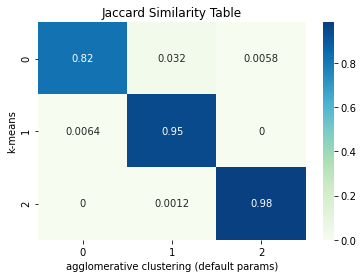

In [48]:
table = get_jaccard_table(pca_df["agglomerative"], pca_df["kmeans"])
plot_jaccard_heatmap(table, "Jaccard Similarity Table", "agglomerative clustering (default params)", "k-means")

Took 18.066221714019775 seconds


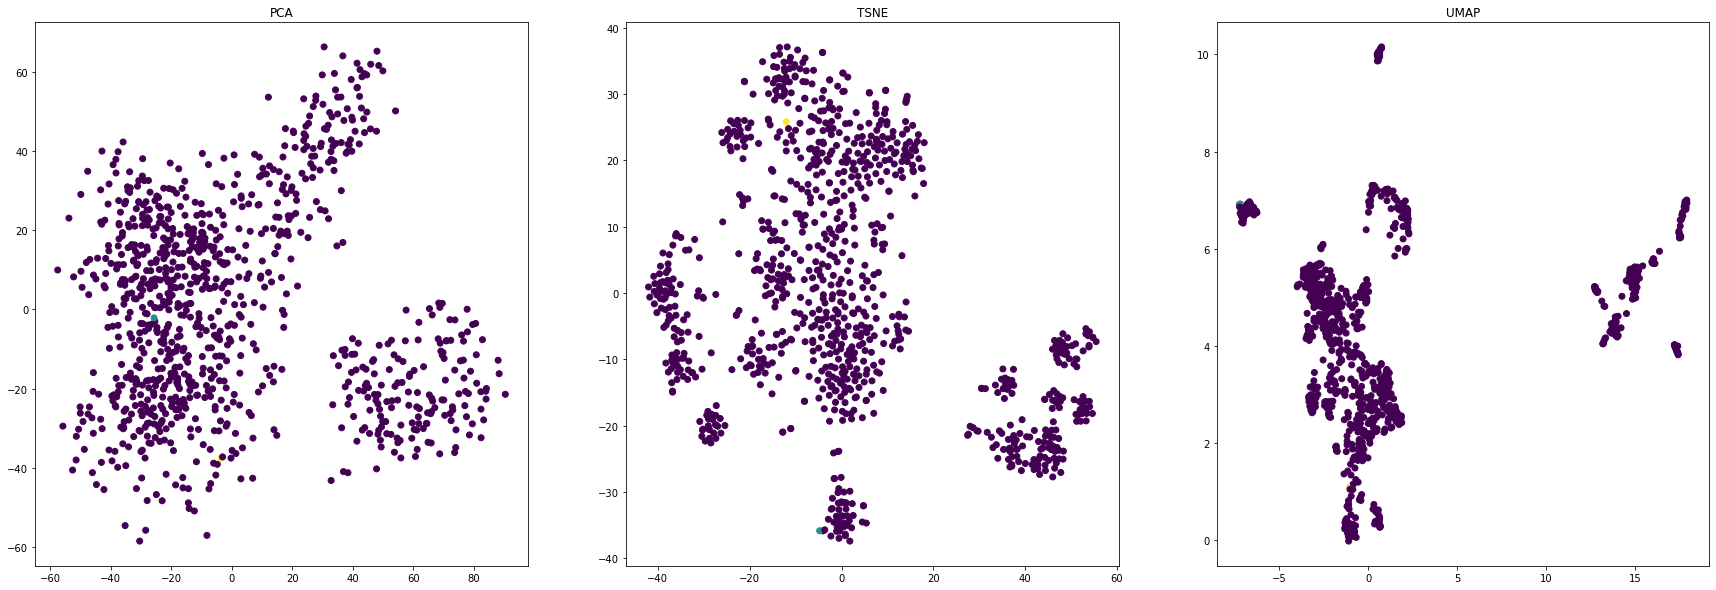

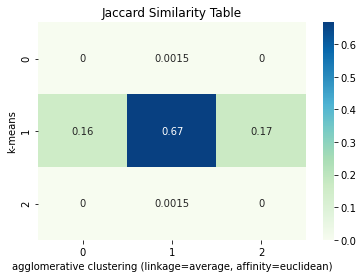

In [56]:
agglomerative_eucliden = AgglomerativeClustering(n_clusters=3, linkage="average", affinity="euclidean")
y_predicted = print_runtime(lambda: agglomerative_eucliden.fit_predict(scaled_data))
y_predicted = homogenize_labels(y_predicted)


for d in dfs:
    d["agglomerative euclidean"] = homogenize_labels(y_predicted)

visualize2d(xs, ys, dfs, titles=methods, cs=[d["agglomerative euclidean"] for d in dfs])    
plt.show()

table = get_jaccard_table(y_predicted, pca_df["kmeans"])
plot_jaccard_heatmap(table, "Jaccard Similarity Table", "agglomerative clustering (linkage=average, affinity=euclidean)", "k-means")

Took 18.21688199043274 seconds


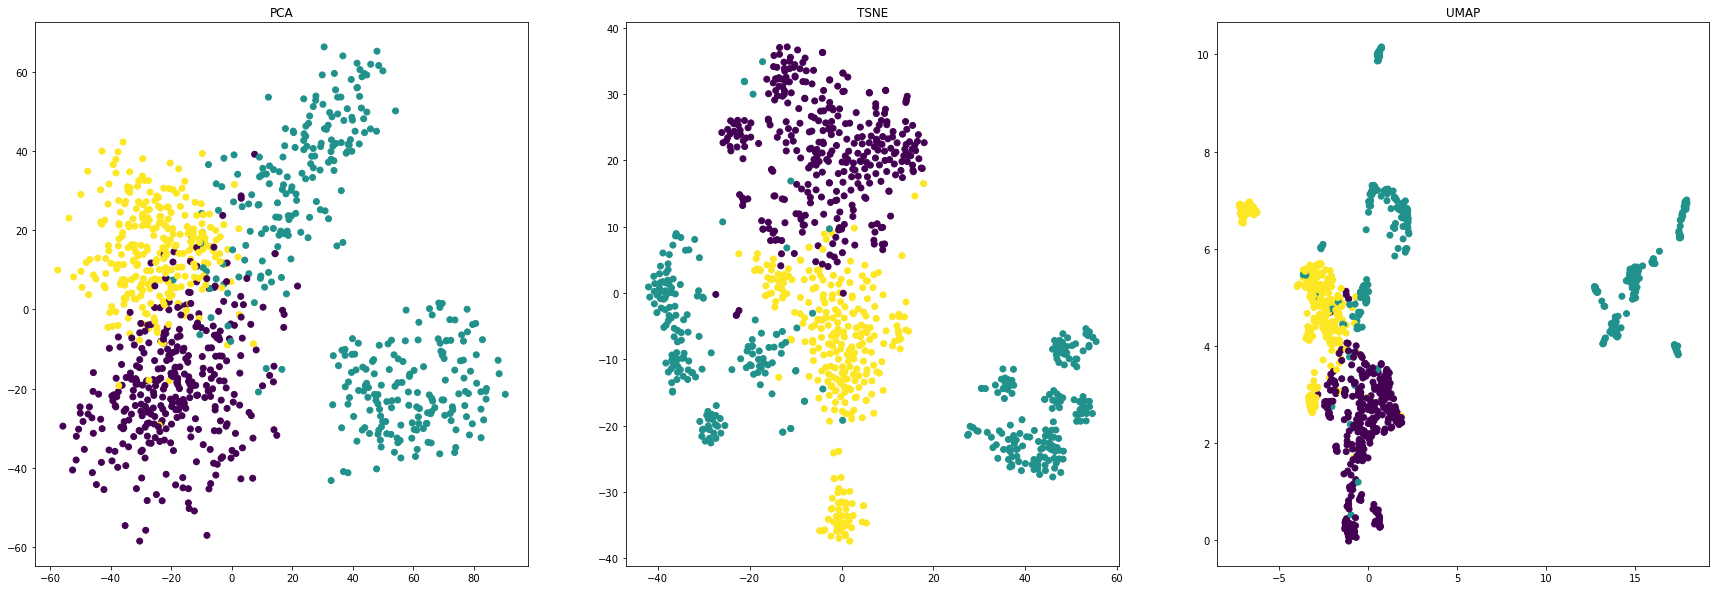

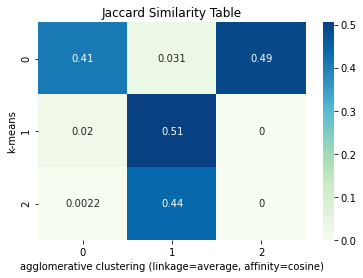

In [57]:
agglomerative_cosine = AgglomerativeClustering(n_clusters=3, linkage="average", affinity="cosine")
y_predicted = print_runtime(lambda: agglomerative_cosine.fit_predict(scaled_data))
#y_predicted = homogenize_labels(y_predicted)

for d in dfs:
    d["agglomerative cosine"] = homogenize_labels(y_predicted)

visualize2d(xs, ys, dfs, titles=methods, cs=[d["agglomerative cosine"] for d in dfs])    
plt.show()


table = get_jaccard_table(y_predicted, pca_df["kmeans"])
plot_jaccard_heatmap(table, "Jaccard Similarity Table", "agglomerative clustering (linkage=average, affinity=cosine)", "k-means")

In [329]:
# read the drug response data 
# columns = cell lines, rows = drugs 
drug_responses = pd.read_csv("data/gdsc_dr.csv")
drug_responses.columns.values[0] = "drug"
drug_responses.head()

,drug,906877,906798,906872,906873,906870,906871,906793,906792,906791,...,907317,907318,907319,1299059,684059,684052,684057,687807,684055,1322213
0,bicalutamide,4.045834,4.211041,4.049380,NaN,3.877443,4.500876,3.787139,NaN,4.193300,...,4.774280,3.337663,3.945140,5.135895,4.112421,4.237832,4.483345,5.578226,4.339973,4.932305
1,bleomycin,3.222664,-1.211779,-0.256964,6.107328,-1.078430,0.214949,-1.128933,-0.248431,3.182742,...,-1.752675,1.001233,-0.112555,3.213554,-0.465512,2.377093,1.680966,3.103060,0.297434,NaN
2,cetuximab,6.891379,5.296735,5.801584,NaN,6.445177,5.516893,5.942849,NaN,NaN,...,6.233908,4.983111,5.504881,6.809426,5.918903,6.387324,6.393561,6.371143,4.952125,6.598547
3,cisplatin,2.105065,0.796922,2.761949,2.579232,4.219197,0.655187,0.307324,1.366857,1.002707,...,4.408282,NaN,NaN,1.712076,0.877124,NaN,1.131967,5.327995,NaN,4.655686
4,dabrafenib,1.952287,4.046885,0.753324,NaN,1.309017,3.102128,-3.994072,NaN,3.326882,...,4.782466,4.612101,4.295890,5.035101,1.694558,1.124854,2.190806,4.692428,1.751297,4.669897


In [330]:
# we select Doxorubicin as the chemotherapy medication of interest
dox = drug_responses.loc[drug_responses["drug"] == "doxorubicin"]
dox = dox.drop(columns=["drug"])
dox = dox.T
dox

,6
906877,-1.174680
906798,-3.972152
906872,-2.539475
906873,-0.563974
906870,-1.839028
...,...
684052,-1.545769
684057,-0.158986
687807,-0.874507
684055,-2.935656


In [331]:
# read the data 
expression = pd.read_csv("data/gdsc_expr_postCB.csv")

# visualize the top 5 rows 
expression.drop(expression.columns[0], axis=1, inplace=True)
expression = expression.transpose()

expression["drug"] = dox
cols = expression.shape[0]
# drop cell lines with missing drug responses 
expression.dropna(inplace=True)
expression.head()
print(cols - expression.shape[0], "cell lines dropped")

y = expression["drug"]
X = expression.drop(columns="drug")
# X = StandardScaler().fit_transform(X)

107 cell lines dropped


In [332]:
from sklearn import linear_model 
from sklearn.model_selection import train_test_split


train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.1)

lasso = linear_model.Lasso(alpha=0.2, max_iter=10000)
lasso.fit(train_X, train_y)
lasso.score(test_X, test_y)

0.13384268244242536

In [333]:
lasso.score(train_X, train_y)

0.19546742767886383

In [ ]:
lasso.score(test_X, test_y)